# Logistic Regression Baseline (V2)
Changes from V1

- Domain + Sentiment Label stratification
- Removal of conflicting samples
- Updated train/validation/test partitions
- Updated external validation dataset

Objective

Re-evaluate the TF-IDF + Logistic Regression baseline
using the corrected dataset partitions.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

base_path = "/content/drive/MyDrive/crossDomainSentAnlys/"

train_df = pd.read_csv(base_path + "train_4domain_natural.csv")
val_df = pd.read_csv(base_path + "val_4domain_natural.csv")
test_df = pd.read_csv(base_path + "test_4domain_natural.csv")

In [4]:
print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(210585, 4)
(30084, 4)
(60168, 4)


In [5]:
pd.crosstab(
    train_df["Domain"],
    train_df["label"]
)

label,Negative,Positive
Domain,,
Hotel Reviews,4345,3322
Movie Reviews,15695,15665
Product Reviews,10347,153476
Tweets,3476,4259


In [6]:
print("Train Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)
print("Test Shape:", test_df.shape)

Train Shape: (210585, 4)
Validation Shape: (30084, 4)
Test Shape: (60168, 4)


In [7]:
pd.crosstab(
    train_df["Domain"],
    train_df["label"],
    margins=True
)


label,Negative,Positive,All
Domain,,,
Hotel Reviews,4345,3322,7667
Movie Reviews,15695,15665,31360
Product Reviews,10347,153476,163823
Tweets,3476,4259,7735
All,33863,176722,210585


In [8]:
pd.crosstab(
    val_df["Domain"],
    val_df["label"],
    margins=True
)

label,Negative,Positive,All
Domain,,,
Hotel Reviews,621,475,1096
Movie Reviews,2242,2238,4480
Product Reviews,1478,21925,23403
Tweets,497,608,1105
All,4838,25246,30084


In [9]:
pd.crosstab(
    test_df["Domain"],
    test_df["label"],
    margins=True
)

label,Negative,Positive,All
Domain,,,
Hotel Reviews,1241,949,2190
Movie Reviews,4485,4475,8960
Product Reviews,2957,43851,46808
Tweets,993,1217,2210
All,9676,50492,60168


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [11]:
def run_in_domain(domain_name):

    train_domain = train_df[
        train_df["Domain"] == domain_name
    ]

    test_domain = test_df[
        test_df["Domain"] == domain_name
    ]

    vectorizer = TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )

    X_train = vectorizer.fit_transform(
        train_domain["text"]
    )

    X_test = vectorizer.transform(
        test_domain["text"]
    )

    model = LogisticRegression(
        random_state=42,
        max_iter=1000
    )

    model.fit(
        X_train,
        train_domain["label"]
    )

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
        test_domain["label"],
        y_pred
    )

    precision = precision_score(
        test_domain["label"],
        y_pred,
        pos_label="Positive"
    )

    recall = recall_score(
        test_domain["label"],
        y_pred,
        pos_label="Positive"
    )

    macro_f1 = f1_score(
        test_domain["label"],
        y_pred,
        average="macro"
    )

    return {
        "Domain": domain_name,
        "Train_Size": len(train_domain),
        "Test_Size": len(test_domain),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "Macro_F1": macro_f1,
        "y_true": test_domain["label"],
        "y_pred": y_pred
    }

In [12]:
product_result = run_in_domain(
    "Product Reviews"
)

movie_result = run_in_domain(
    "Movie Reviews"
)

hotel_result = run_in_domain(
    "Hotel Reviews"
)

tweet_result = run_in_domain(
    "Tweets"
)

In [13]:
results = [
    product_result,
    movie_result,
    hotel_result,
    tweet_result
]

results_df = pd.DataFrame([
    {
        "Domain": r["Domain"],
        "Train_Size": r["Train_Size"],
        "Test_Size": r["Test_Size"],
        "Accuracy": r["Accuracy"],
        "Precision": r["Precision"],
        "Recall": r["Recall"],
        "Macro_F1": r["Macro_F1"]
    }
    for r in results
])

results_df.round(4)

,Domain,Train_Size,Test_Size,Accuracy,Precision,Recall,Macro_F1
0,Product Reviews,163823,46808,0.9540,0.9571,0.9956,0.7286
1,Movie Reviews,31360,8960,0.9153,0.9196,0.9099,0.9153
2,Hotel Reviews,7667,2190,0.9470,0.9675,0.9083,0.9456
3,Tweets,7735,2210,0.8443,0.8184,0.9219,0.8397


<Figure size 500x400 with 0 Axes>

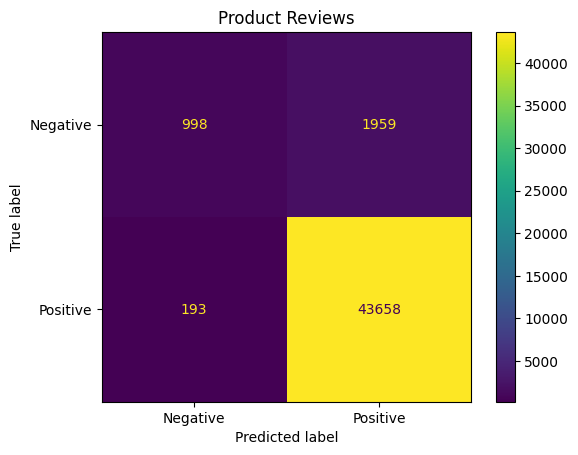

<Figure size 500x400 with 0 Axes>

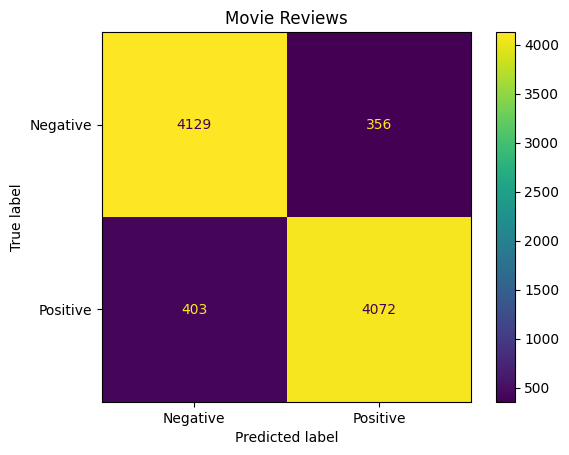

<Figure size 500x400 with 0 Axes>

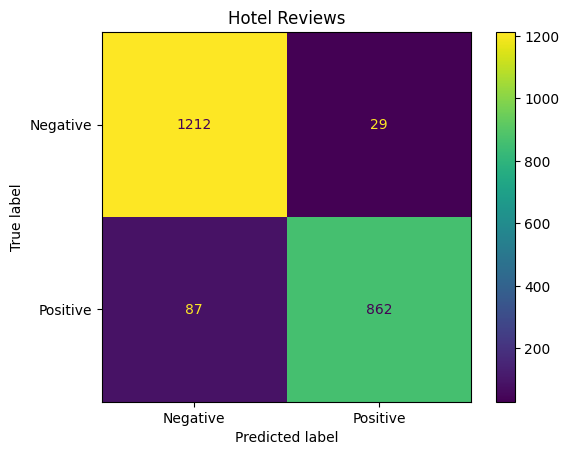

<Figure size 500x400 with 0 Axes>

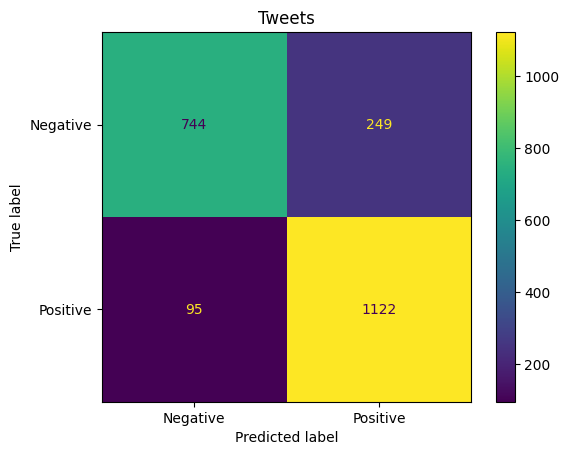

In [14]:
for result in results:

    plt.figure(figsize=(5,4))

    ConfusionMatrixDisplay.from_predictions(
        result["y_true"],
        result["y_pred"]
    )

    plt.title(result["Domain"])

    plt.show()

## Summary

The Logistic Regression baseline was rerun using the corrected dataset partitions generated through Domain + Sentiment Label stratification.

The resulting performance remained largely consistent with the initial baseline while providing more reliable and reproducible evaluation conditions.

The training and evaluation pipeline has been successfully verified and is ready for the initial BERTurk experiment (seed = 42).